In [16]:
from pathlib import Path

import h3
import cdsapi
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rasterio
import rioxarray as rxr
from rasterio.merge import merge
from rasterio.enums import Resampling
from shapely.geometry import Polygon, Point

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import to_hex

YEAR = "2026"
VAR = "hot_days"    # "hot_days" o "tropical_nights"#
CRS = "EPSG:4326"  # WGS84

DATA_DIR = Path("../data/external")
DATA_DIR.mkdir(exist_ok=True)

OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

In [17]:
era5_path = DATA_DIR / "era5land_t2m_2026.nc"

# Cargamos los datos de ERA5-Land (descargados previamente o descargados ahora)
if era5_path.exists():
    ds = xr.open_dataset(era5_path)
else:
    c = cdsapi.Client()
    c.retrieve(
        "reanalysis-era5-land",
        {
            "variable": ["2m_temperature"],
            "year": [YEAR],
            "month": ["05", "06", "07", "08"],
            "day": [f"{d:02d}" for d in range(1, 32)],
            "time": [f"{h:02d}:00" for h in range(24)],
            "area": [49.1, 9.4, 46.3, 17.3],   # N, W, S, E (Austria + margen)
            "data_format": "netcdf",
            "download_format": "unarchived",
        },
        era5_path,
    )
    ds = xr.open_dataset(era5_path)

# Compatibilidad con el formato nuevo del CDS
if "valid_time" in ds.coords:
    ds = ds.rename({"valid_time": "time"})
ds = ds.drop_vars([v for v in ["number", "expver"] if v in ds.coords], errors="ignore")

t = ds["t2m"] - 273.15                       # K -> °C

# UTC -> hora local de verano (CEST = UTC+2 durante todo jun-ago)
t = t.assign_coords(time=t["time"] + np.timedelta64(2, "h"))

# Resampleamos a diario y seleccionamos el periodo de interés
tmax = t.resample(time="1D").max().sel(time=slice("2026-06-01", "2026-08-31"))
tmin = t.resample(time="1D").min().sel(time=slice("2026-06-01", "2026-08-31"))

# Calculamos los días calurosos y las noches tropicales
counts = xr.Dataset({
    "hot_days": (tmax >= 30).sum("time").astype(float),
    "tropical_nights": (tmin >= 20).sum("time").astype(float),
})
counts

<xarray.Dataset> Size: 38kB
Dimensions:          (latitude: 29, longitude: 80)
Coordinates:
  * latitude         (latitude) float64 232B 49.1 49.0 48.9 ... 46.5 46.4 46.3
  * longitude        (longitude) float64 640B 9.4 9.5 9.6 9.7 ... 17.1 17.2 17.3
Data variables:
    hot_days         (latitude, longitude) float64 19kB 30.0 29.0 ... 42.0 44.0
    tropical_nights  (latitude, longitude) float64 19kB 12.0 11.0 ... 36.0 34.0

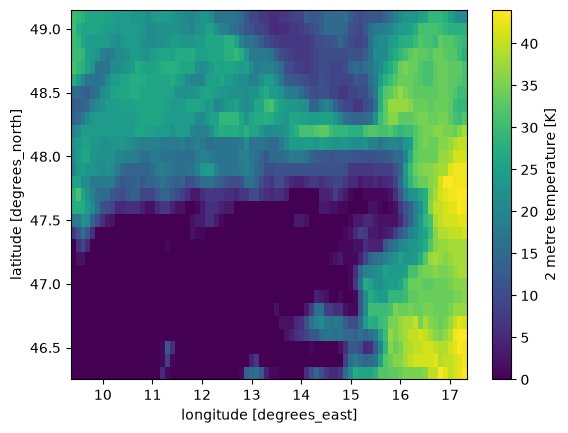

In [18]:
counts["hot_days"].plot()

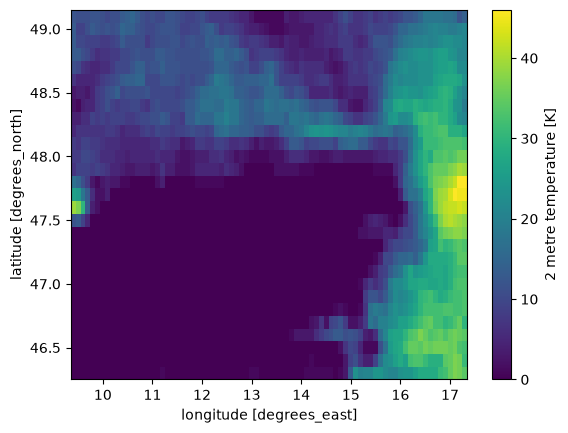

In [19]:
counts["tropical_nights"].plot()

In [20]:
DEM_OUT = DATA_DIR / "dem_austria.tif"

# Definimos el bounding box y la base URL para descargar el DEM de Copernicus (30 m)
BBOX_W, BBOX_S, BBOX_E, BBOX_N = 9.4, 46.3, 17.3, 49.1
BASE = "https://copernicus-dem-30m.s3.amazonaws.com"

if DEM_OUT.exists():
    print("DEM ya existe en", DEM_OUT)
else:
    def tile_url(lat, lon):
        ns = f"N{lat:02d}" if lat >= 0 else f"S{abs(lat):02d}"
        ew = f"E{lon:03d}" if lon >= 0 else f"W{abs(lon):03d}"
        name = f"Copernicus_DSM_COG_10_{ns}_00_{ew}_00_DEM"
        return f"{BASE}/{name}/{name}.tif"

    # Cada tile cubre 1°x1°, el nombre indica la esquina suroeste
    lats = range(int(np.floor(BBOX_S)), int(np.floor(BBOX_N)) + 1)
    lons = range(int(np.floor(BBOX_W)), int(np.floor(BBOX_E)) + 1)

    srcs = []
    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
        GDAL_HTTP_MAX_RETRY="3", GDAL_HTTP_RETRY_DELAY="1"):
        for la in lats:
            for lo in lons:
                url = tile_url(la, lo)
                try:
                    srcs.append(rasterio.open(url))
                except Exception as e:
                    print("Sin tile:", la, lo, "->", type(e).__name__)

        print(len(srcs), "tiles abiertos")

        # merge con 'res' remuestrea al leer (usa los overviews del COG, no baja los 30 m completos)
        mosaic, transform = merge(
            srcs,
            bounds=(BBOX_W, BBOX_S, BBOX_E, BBOX_N),
            res=0.01,
            resampling=Resampling.average,
            nodata=-9999,
        )

        profile = srcs[0].profile.copy()
        profile.update(
            driver="GTiff", height=mosaic.shape[1], width=mosaic.shape[2],
            transform=transform, count=1, dtype="float32", nodata=-9999,
            compress="deflate", tiled=True,
        )
        for s in srcs:
            s.close()

    with rasterio.open(DEM_OUT, "w", **profile) as dst:
        dst.write(mosaic.astype("float32"))

    print("DEM guardado en", DEM_OUT, "| shape:", mosaic.shape)

# Abrimos el DEM y lo reproyectamos a WGS84
dem = rxr.open_rasterio(DATA_DIR / "dem_austria.tif", masked=True).squeeze(drop=True)
# DEM fino -> EPSG:4326 a 0.01° (~1 km), promediando
dem = dem.rio.reproject(CRS, resolution=0.01, resampling=Resampling.average)
dem = dem.rename({"x": "longitude", "y": "latitude"}).sortby(["latitude", "longitude"])
dem = dem.drop_vars("spatial_ref", errors="ignore")

DEM ya existe en ..\data\external\dem_austria.tif


In [21]:
era5land_path = DATA_DIR / "era5land_z.nc"

if era5land_path.exists():
    zds = xr.open_dataset(era5land_path)
else:
    c.retrieve(
        "reanalysis-era5-land",
        {
            "variable": ["geopotential"],
            "year": "2026", "month": "01", "day": "01", "time": "00:00",
            "area": [49.1, 9.4, 46.3, 17.3],
            "data_format": "netcdf",
            "download_format": "unarchived",
        },
        era5land_path,
    )
    zds = xr.open_dataset(era5land_path)

# Altitud "vista" por ERA5-Land (m)
zds = zds.rename({"valid_time": "time"}) if "valid_time" in zds.coords else zds
z_coarse = (zds["z"].squeeze(drop=True) / 9.80665)
z_coarse = z_coarse.drop_vars([v for v in ["time", "number", "expver"] if v in z_coarse.coords])
z_coarse = z_coarse.sortby(["latitude", "longitude"])

# Interpolo la altitud gruesa a la malla fina
z_c_fine = z_coarse.interp(latitude=dem.latitude, longitude=dem.longitude, method="linear")

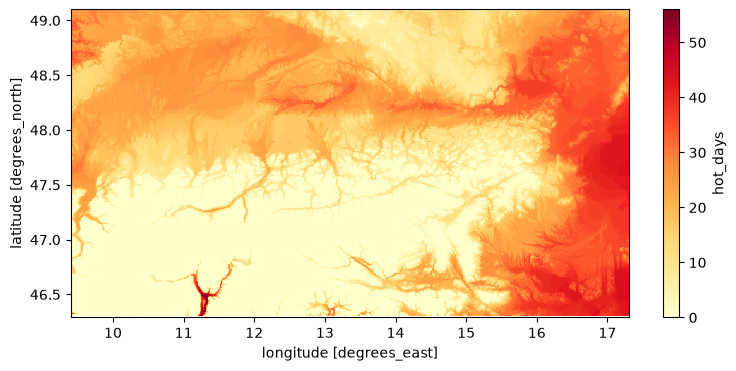

In [22]:
GAMMA = -0.0065   # K por metro (gradiente estándar)

# Ajuste de temperatura por altitud
tmax_c = tmax.sortby(["latitude", "longitude"])
tmax_c_fine = tmax_c.interp(
    latitude=dem.latitude, longitude=dem.longitude, method="linear").astype("float32")

dz = (dem - z_c_fine).astype("float32")          # altitud real - altitud ERA5-Land
tmax_fine = tmax_c_fine + GAMMA * dz              # broadcast sobre 'time'
tmax_fine = tmax_fine.where(dem.notnull())        # implementing mask to avoid NaN values in areas without DEM data

tmin_c = tmin.sortby(["latitude", "longitude"])
tmin_c_fine = tmin_c.interp(
    latitude=dem.latitude, longitude=dem.longitude, method="linear").astype("float32")
tmin_fine = tmin_c_fine + GAMMA * dz
tmin_fine = tmin_fine.where(dem.notnull())

counts_fine = xr.Dataset({
    "hot_days": (tmax_fine >= 30).sum("time").astype(float).where(dem.notnull()),
    "tropical_nights": (tmin_fine >= 20).sum("time").astype(float).where(dem.notnull())
})
counts_fine = counts_fine.drop_vars("spatial_ref", errors="ignore")

counts_fine["hot_days"].plot(cmap="YlOrRd", figsize=(9, 4))   # control visual

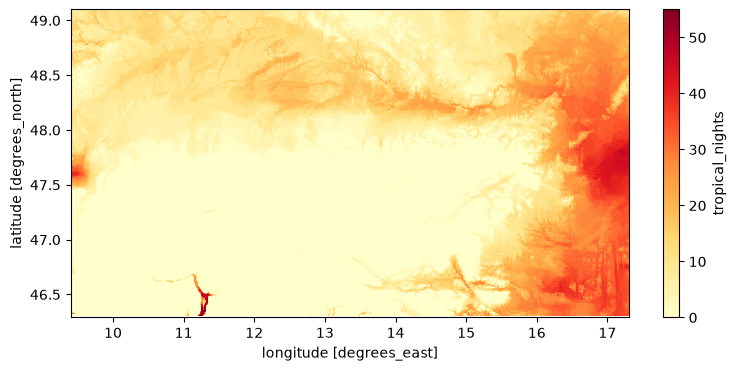

In [23]:
counts_fine["tropical_nights"].plot(cmap="YlOrRd", figsize=(9, 4)) 

In [24]:
H3_RES = 6   # ~36 km² por hexágono, unos 2 300 en Austria (vs ~330 con res 5)

df = counts_fine.to_dataframe().reset_index().dropna()
# df["tropical_nights"] = np.nan    # esta variable no se downscalea (ver notas)

df["h3"] = [h3.latlng_to_cell(la, lo, H3_RES)
            for la, lo in zip(df["latitude"], df["longitude"])]

hexv = df.groupby("h3")[["hot_days", "tropical_nights"]].mean()

def hex_polygon(cell):
    # h3 devuelve (lat, lng); shapely necesita (x=lng, y=lat)
    return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])

gdf = gpd.GeoDataFrame(
    hexv,
    geometry=[hex_polygon(c) for c in hexv.index],
    crs=CRS,
)
gdf["center"] = [Point(h3.cell_to_latlng(c)[::-1]) for c in gdf.index]
print(len(gdf), "hexágonos")

5346 hexágonos


In [25]:
austria = gpd.read_file(DATA_DIR / "austria_boundary.gpkg").to_crs(CRS)
austria = austria.assign(_k=1).dissolve(by="_k").reset_index(drop=True)[["geometry"]]
austria["geometry"] = austria.geometry.make_valid()
aut_geom = austria.geometry.iloc[0]
print("Filas tras disolver:", len(austria), "| tipo:", aut_geom.geom_type)

centers = gpd.GeoSeries(gdf["center"], index=gdf.index, crs=CRS)

gdf = gdf[centers.within(aut_geom)].drop(columns="center").copy()
print(len(gdf), "hexágonos dentro de Austria")

Filas tras disolver: 1 | tipo: MultiPolygon
2340 hexágonos dentro de Austria


In [26]:
states_path = DATA_DIR / "austria_states.gpkg"

if not states_path.exists():
    adm1 = gpd.read_file(
        "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip"
    )
    adm1.columns = adm1.columns.str.lower()          # los nombres de columna varían entre versiones
    states = adm1[adm1["adm0_a3"] == "AUT"][["name", "geometry"]].to_crs(CRS)
    states.to_file(states_path, driver="GPKG")

states = gpd.read_file(states_path)
print(len(states), "Bundesländer:", sorted(states["name"].tolist()))

9 Bundesländer: ['Burgenland', 'Kärnten', 'Niederösterreich', 'Oberösterreich', 'Salzburg', 'Steiermark', 'Tirol', 'Vorarlberg', 'Wien']


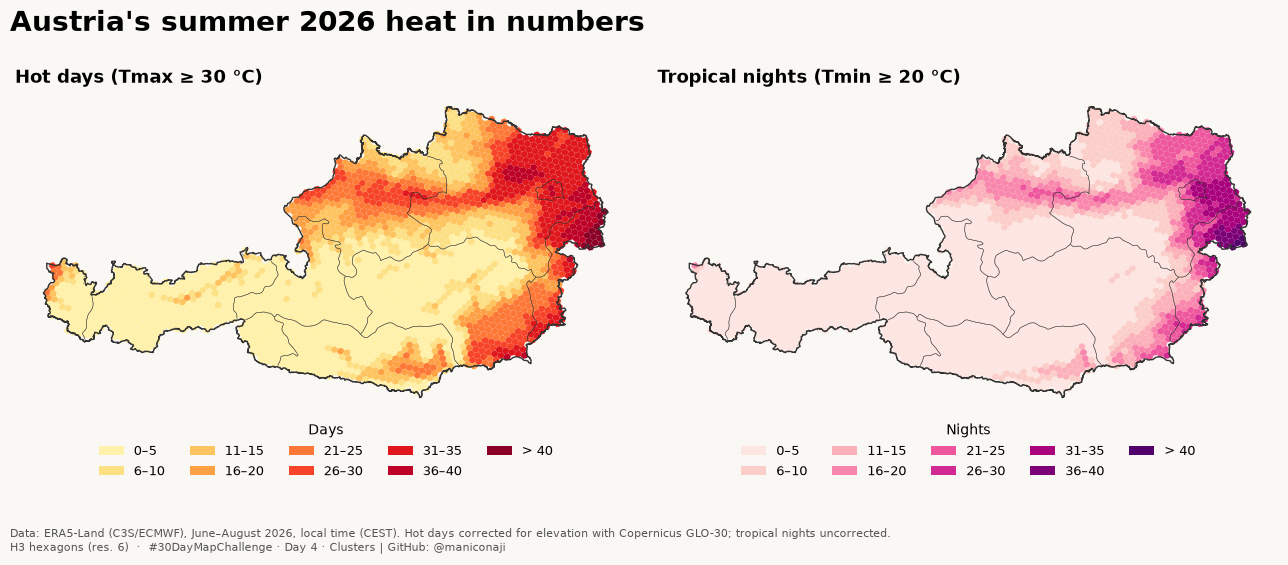

In [27]:
crs_plot = "EPSG:31287"
g = gdf.to_crs(crs_plot).copy()
a = austria.to_crs(crs_plot)
st = states.to_crs(crs_plot)

# Intersección explícita, geometría a geometría
inner_area = a.geometry.iloc[0].buffer(-1500)
lines = st.boundary.intersection(inner_area)
state_lines = gpd.GeoSeries(lines[~lines.is_empty], crs=crs_plot)

# Clases: 0–5, 6–10, 11–15, 16–20, 21–25, 26–30, 31–35, 36–40, > 40  (redondeo a días enteros antes de clasificar)
edges  = [-np.inf, 5, 10, 15, 20, 25, 30, 35, 40, np.inf]
labels = ["0–5", "6–10", "11–15", "16–20", "21–25", "26–30", "31–35", "36–40", "> 40"]

def classify(series):
    # Redondea a días enteros y clasifica en bins definidos por 'edges' y 'labels'
    return pd.cut(np.rint(series), bins=edges, labels=labels, right=True)

# Clasifica los datos en las clases definidas
g["hot_cls"]  = classify(g["hot_days"])
g["trop_cls"] = classify(g["tropical_nights"])

def palette(cmap_name):
    # Devuelve un diccionario {label: color_hex} para la paleta de colores de matplotlib
    cmap = plt.get_cmap(cmap_name)
    return dict(zip(labels, [to_hex(cmap(v)) for v in np.linspace(0.1, 0.98, len(labels))]))

# Definición de los paneles a mostrar en la figura
panels = [
    ("hot_cls",  "Hot days (Tmax ≥ 30 °C)",        palette("YlOrRd")),
    ("trop_cls", "Tropical nights (Tmin ≥ 20 °C)", palette("RdPu")),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), facecolor="#faf8f4")

for ax, (col, title, pal) in zip(axes, panels):
    ax.set_facecolor("#faf8f4")
    colors = g[col].astype(object).map(pal).fillna("#e9e6e0")
    g.plot(ax=ax, color=colors, edgecolor="none")
    a.boundary.plot(ax=ax, color="#333", linewidth=1.0)
    state_lines.plot(ax=ax, color="#333", linewidth=0.35, alpha=0.8)
    ax.set_title(title, fontsize=13, loc="left", fontweight="bold")
    ax.set_axis_off()
    if "Hot days" in title:
        ax.legend(
            handles=[Patch(facecolor=pal[l], label=l) for l in labels],
            title="Days", loc="upper center", bbox_to_anchor=(0.5, 0.0),
            ncol=5, frameon=False, fontsize=9, title_fontsize=10,)
    elif "Tropical nights" in title:
        ax.legend(
            handles=[Patch(facecolor=pal[l], label=l) for l in labels],
            title="Nights", loc="upper center", bbox_to_anchor=(0.5, 0.0),
            ncol=5, frameon=False, fontsize=9, title_fontsize=10,)

# definir titulo de la figura
fig.suptitle(
    "Austria's summer 2026 heat in numbers", 
    x = 0.01, y = 0.95, 
    ha="left", 
    fontsize=20, 
    fontweight="bold")

# información relevante
fig.text(
    0.01, 0.01,
    "Data: ERA5-Land (C3S/ECMWF), June–August 2026, local time (CEST). Hot days corrected for elevation "
    "with Copernicus GLO-30; tropical nights uncorrected.\n"
    "H3 hexagons (res. 6)  ·  #30DayMapChallenge · Day 4 · Clusters | GitHub: @maniconaji",
    fontsize=8, 
    color="#555", 
    ha="left", 
    va="bottom")

fig.tight_layout(rect=(0, 0.2, 1, 0.94))
fig.savefig(OUT / "day04_heat_hotdays_tropicalnights_austria.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# cells = gdf.index.tolist()
# cellset = set(cells)
# K_RING = 2
# neighbors = {
#     c: [n for n in h3.grid_disk(c, K_RING) if n != c and n in cellset]
#     for c in cells
# }
# w = W(neighbors, silence_warnings=True)

# print("Islas (sin vecinos):", w.islands)
# print("Vecinos promedio:", round(w.mean_neighbors, 2))

In [29]:
# np.random.seed(42)

# order = list(w.id_order)              # mismo orden que usa W
# y = gdf.loc[order, VAR].values

# lg = G_Local(y, w, transform="B", star=True, permutations=999)

# gdf.loc[order, "z"] = lg.Zs
# gdf.loc[order, "p_sim"] = lg.p_sim

# # Clasificación por nivel de confianza (umbrales z clásicos)
# z = gdf["z"]
# conds = [z >= 2.58, z >= 1.96, z >= 1.65,
#          z <= -2.58, z <= -1.96, z <= -1.65]
# labels = ["Hot spot 99 %", "Hot spot 95 %", "Hot spot 90 %",
#           "Cold spot 99 %", "Cold spot 95 %", "Cold spot 90 %"]
# gdf["cluster"] = np.select(conds, labels, default="No significativo")
# gdf["cluster"].value_counts()

In [30]:
# crs_plot = "EPSG:31287"   # MGI / Austria Lambert
# g = gdf.to_crs(crs_plot)
# a = austria.to_crs(crs_plot)

# colors = {
#     "Hot spot 99 %":  "#b30000",
#     "Hot spot 95 %":  "#e34a33",
#     "Hot spot 90 %":  "#fc8d59",
#     "No significativo": "#e9e6e0",
#     "Cold spot 90 %": "#9ecae1",
#     "Cold spot 95 %": "#4292c6",
#     "Cold spot 99 %": "#08519c",
# }

# fig, ax = plt.subplots(figsize=(11, 6), facecolor="#faf8f4")
# ax.set_facecolor("#faf8f4")

# g.plot(ax=ax, color=g["cluster"].map(colors), edgecolor="white", linewidth=0.4)
# a.boundary.plot(ax=ax, color="#222", linewidth=0.7)

# present = [k for k in colors if k in g["cluster"].values]
# ax.legend(
#     handles=[Patch(facecolor=colors[k], label=k) for k in present],
#     title="Getis-Ord Gi*", loc="lower left", frameon=False,
# )

# nombre = "Días de calor (Tmax ≥ 30 °C)" if VAR == "hot_days" else "Noches tropicales (Tmin ≥ 20 °C)"
# ax.set_title(f"Clusters de calor en Austria · {nombre}\nverano 2026",
#              fontsize=15, loc="left", fontweight="bold")
# ax.text(0.99, 0.01,
#         "Datos: ERA5-Land (C3S/ECMWF) · Hexágonos H3 res. 5 · Gi* con 9 999 permutaciones\n"
#         "#30DayMapChallenge · Día 4 · Clusters",
#         transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color="#555")
# ax.set_axis_off()

# fig.savefig(OUT / "day04_clusters_calor_austria.png", dpi=300, bbox_inches="tight")
# plt.show()